# 06 - Explainability: SHAP values and partial dependence

## Goal of this notebook, in simple terms

The GBM predicts claim frequency better than the GLM (notebooks 03 and 05), but it is a sum of
hundreds of trees: nobody can read it directly. An insurer cannot use a price it cannot explain -
to managers, to regulators, or to a customer who asks *"why is my premium so high?"*.

Here we open the black box and answer three questions:

1. **Which factors matter most** for the GBM, and is that consistent with the GLM? (global importance)
2. **How does each factor move the prediction** - the shape of the effect, and how it compares
   with the GLM relativities? (dependence and partial dependence plots)
3. **Where does the GBM's extra accuracy come from?** We test the hypothesis from notebooks 02-03
   that it captures an **age × bonus-malus interaction**. (SHAP interaction values)

And finally: **why did this particular customer get this price?** (local explanations)

We work on the frequency models (where the GBM made the difference) and end with a short look at
severity.

In [1]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from motor_pricing import PROJECT_ROOT
from motor_pricing.data import load_processed
from motor_pricing.features import gbm_features, glm_features, GBM_CATEGORICAL
from motor_pricing.models import FrequencyGLM, FrequencyGBM, SeverityGBM
from motor_pricing.explain import ice_curves, partial_dependence
from motor_pricing.validation import split_train_test
from motor_pricing.plotting import set_style, save, SERIES, INK_2, GRID, MODEL_COLORS

set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
df = load_processed()
train, test = split_train_test(df, test_size=0.2)

freq_params = json.load(open(PROJECT_ROOT / "models" / "frequency_gbm_params.json"))
glm = FrequencyGLM().fit(train)
gbm = FrequencyGBM(**freq_params).fit(train)
print("frequency GBM:", freq_params, "| trees:", gbm.best_iteration_)

C:\Users\mattr\Desktop\motor-insurance-pricing-model\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


frequency GBM: {'num_leaves': 31, 'min_child_samples': 500, 'learning_rate': 0.05, 'reg_lambda': 10.0} | trees: 456


## 1. SHAP values - theory

**Shapley values** come from cooperative game theory (L. Shapley, 1953): several players cooperate
to produce a payout; how do we share it fairly? The Shapley value of a player is its marginal
contribution, averaged over all possible orders in which the players could join the team.

**SHAP** (Lundberg & Lee, 2017) applies this to a prediction: the "players" are the rating factors,
the "payout" is the difference between this policy's prediction and the average prediction.
For policy $i$:

$$f(x_i) = \phi_0 + \sum_{j=1}^{p} \phi_{ij}$$

* $\phi_0$ = the average model output (base value);
* $\phi_{ij}$ = the contribution of factor $j$ to policy $i$'s prediction.

It is the **only** attribution method with these properties: *efficiency* (contributions add up
exactly to the prediction), *symmetry* (two factors with the same effect get the same credit),
*dummy* (a factor the model does not use gets 0), *additivity*.

**TreeSHAP** computes these values *exactly* and fast for tree ensembles.

**Important for insurance:** our GBM works on the **log scale** (Poisson objective with log link),
so SHAP values add up on the log scale:

$$\hat\lambda_i = e^{\phi_0}\cdot\prod_j e^{\phi_{ij}}$$

$e^{\phi_{ij}}$ is therefore a **multiplicative factor**, exactly like a GLM relativity - but
*personalised*: the same factor value can get different multipliers for different policies when
it interacts with other factors.

*Comparison with the GLM.* For a log-link GLM without interactions and with independent factors,
the SHAP value of factor $j$ is simply $\beta_j (x_{ij} - \bar x_j)$: the coefficient times the
distance from the average. We use this to compare both models on the same scale.

*Caveat.* SHAP explains **the model**, not the world: a large SHAP value means "the model uses this
factor a lot", not "this factor *causes* accidents". With correlated factors (age and BM) credit can
be shared between them in ways that depend on the model.

## 2. Compute SHAP values

**Goal:** compute the contribution of each factor for a random sample of 10,000 test policies
(unseen during training), and check the efficiency property numerically.

In [2]:
sample = test.sample(10_000, random_state=1)
X = gbm_features(sample)
explainer = shap.TreeExplainer(gbm.model_.booster_)
sv = explainer(X)
raw = gbm.model_.predict(X, num_iteration=gbm.best_iteration_, raw_score=True)
print(f"base value phi_0 = {sv.base_values[0]:.4f}  ->  base frequency exp(phi_0) = {np.exp(sv.base_values[0]):.4f}")
print(f"max |sum of SHAP + base - log prediction| = {np.abs(sv.values.sum(1) + sv.base_values - raw).max():.2e}")
shap_df = pd.DataFrame(sv.values, columns=X.columns, index=X.index)

# Numeric copy of the features (categories as codes) for colouring plots / interaction values
Xn = X.copy()
for c in GBM_CATEGORICAL:
    Xn[c] = Xn[c].cat.codes.astype(float)

base value phi_0 = -2.7212  ->  base frequency exp(phi_0) = 0.0658
max |sum of SHAP + base - log prediction| = 2.05e-14


**Interpretation.** The sum of contributions reproduces every log-prediction up to ~1e-14 (machine
precision): the decomposition is exact. The base value $e^{\phi_0}$ is the model's average output on
the log scale (a geometric-type mean, a bit below the portfolio frequency of 0.074 because the
distribution of frequencies is skewed).

## 3. Global importance - which factors matter most?

**Goal:** rank the factors by how much they move predictions on average. Importance of factor $j$ =
mean over policies of $|\phi_{ij}|$ (log scale). We compute the same quantity for the GLM using
$\beta_j(x_{ij}-\bar x_j)$, summing the dummy columns of each categorical factor.

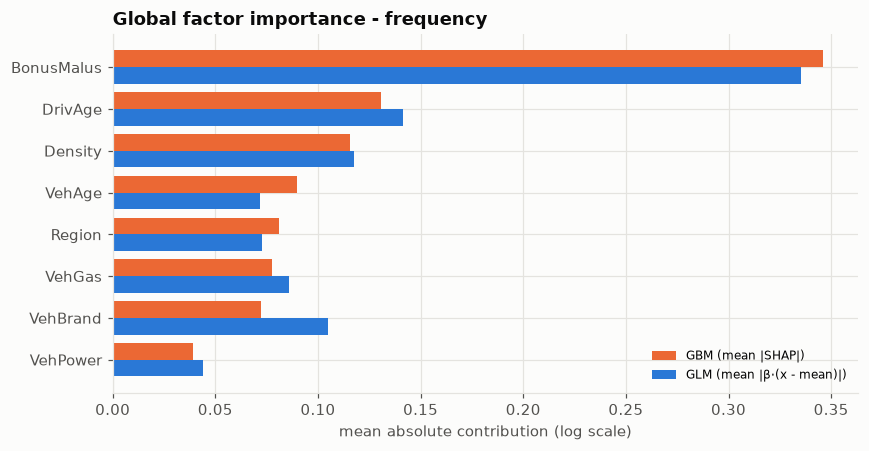

,GBM,GLM,GBM_share,GLM_share
BonusMalus,0.3458,0.3351,0.3633,0.3443
DrivAge,0.1306,0.1415,0.1372,0.1454
Density,0.1156,0.1174,0.1215,0.1206
VehAge,0.0897,0.0719,0.0943,0.0739
Region,0.0811,0.0725,0.0852,0.0745
VehGas,0.0776,0.0860,0.0816,0.0884
VehBrand,0.0723,0.1048,0.0760,0.1076
VehPower,0.0390,0.0439,0.0410,0.0452


In [3]:
Xd = glm.design_.transform(sample)
contrib = (Xd - Xd.mean()) * glm.result_.params
glm_map = {"VehPowerGLM": "VehPower", "VehAgeGLM": "VehAge", "DrivAgeGLM": "DrivAge", "BonusMalusGLM": "BonusMalus",
           "LogDensity": "Density", "VehBrand": "VehBrand", "VehGas": "VehGas", "Region": "Region"}
glm_contrib = pd.DataFrame({new: contrib[[c for c in contrib.columns if c == old or c.startswith(old + "[")]].sum(axis=1)
                            for old, new in glm_map.items()})

importance = pd.DataFrame({"GBM": shap_df.abs().mean(), "GLM": glm_contrib.abs().mean()}).sort_values("GBM")
fig, ax = plt.subplots(figsize=(8, 4.2))
yy = np.arange(len(importance))
ax.barh(yy + 0.2, importance["GBM"], height=0.4, color=MODEL_COLORS["GBM"], label="GBM (mean |SHAP|)")
ax.barh(yy - 0.2, importance["GLM"], height=0.4, color=MODEL_COLORS["GLM"], label="GLM (mean |β·(x - mean)|)")
ax.set(yticks=yy, yticklabels=importance.index, xlabel="mean absolute contribution (log scale)",
       title="Global factor importance - frequency")
ax.legend(fontsize=8, loc="lower right"); plt.tight_layout(); save(fig, "06_importance"); plt.show()
importance.sort_values("GBM", ascending=False).assign(
    GBM_share=lambda d: d["GBM"] / d["GBM"].sum(), GLM_share=lambda d: d["GLM"] / d["GLM"].sum())

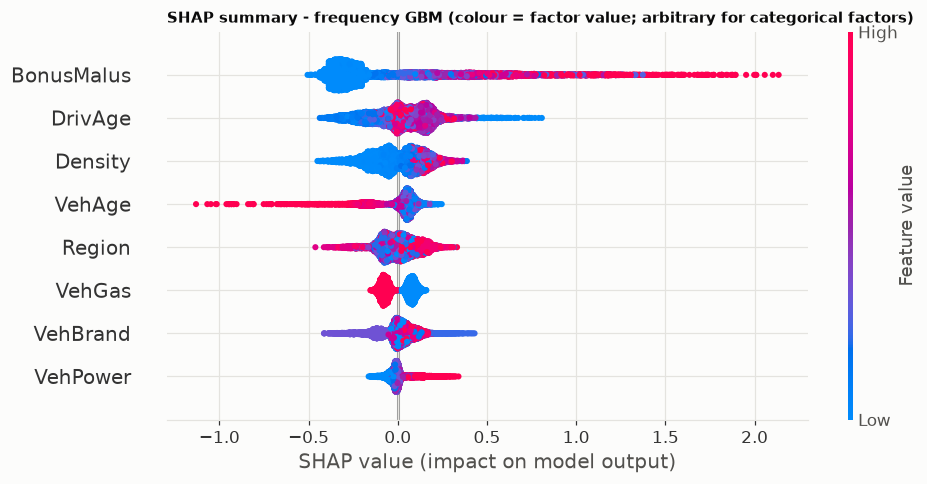

In [4]:
shap.plots.beeswarm(shap.Explanation(sv.values, sv.base_values, data=Xn.to_numpy(), feature_names=list(X.columns)),
                    max_display=8, show=False)
plt.title("SHAP summary - frequency GBM (colour = factor value; arbitrary for categorical factors)", fontsize=10, loc="left")
plt.gcf().set_size_inches(9, 4.5); plt.tight_layout(); save(plt.gcf(), "06_beeswarm"); plt.show()

**Interpretation**

* The two models agree on the **ranking**: **bonus-malus** dominates (~35% of the total absolute
  contribution in both), then **driver age** (~14%) and **density** (~12%); vehicle age, region, fuel
  and brand follow (7-11% each); vehicle power matters least (~4%).
* Differences: the GBM gives a bit more weight to vehicle age (9% vs 7%) and less to brand (8% vs 11%).
* *Beeswarm reading:* for BonusMalus, high values (red) sit far to the right (multipliers up to ~8,
  i.e. $e^{2}$), low values (blue) slightly to the left; the long right tail shows that a few
  policies get very large loadings, while the bulk of the portfolio (BM = 50) gets a modest discount.

*Real-world meaning:* the GBM is not doing anything exotic - it relies on the **same risk factors**
an actuary would use, in the same order of importance. Its advantage must come from *how* it uses
them (shapes and interactions), which is what we examine next. This consistency is also an
important argument when presenting a GBM-based tariff to management or a regulator.

## 4. How does each factor act? SHAP dependence plots

**Goal:** see the *shape* of each effect. Each dot is a policy: x = its value of the factor,
y = the multiplier $e^{\phi_{ij}}$ that the GBM applies because of that factor. A thin vertical
spread means the factor acts the same way for everybody; a wide spread means its effect depends
on other factors (interactions). Colour = driver age band, to reveal the age interaction.

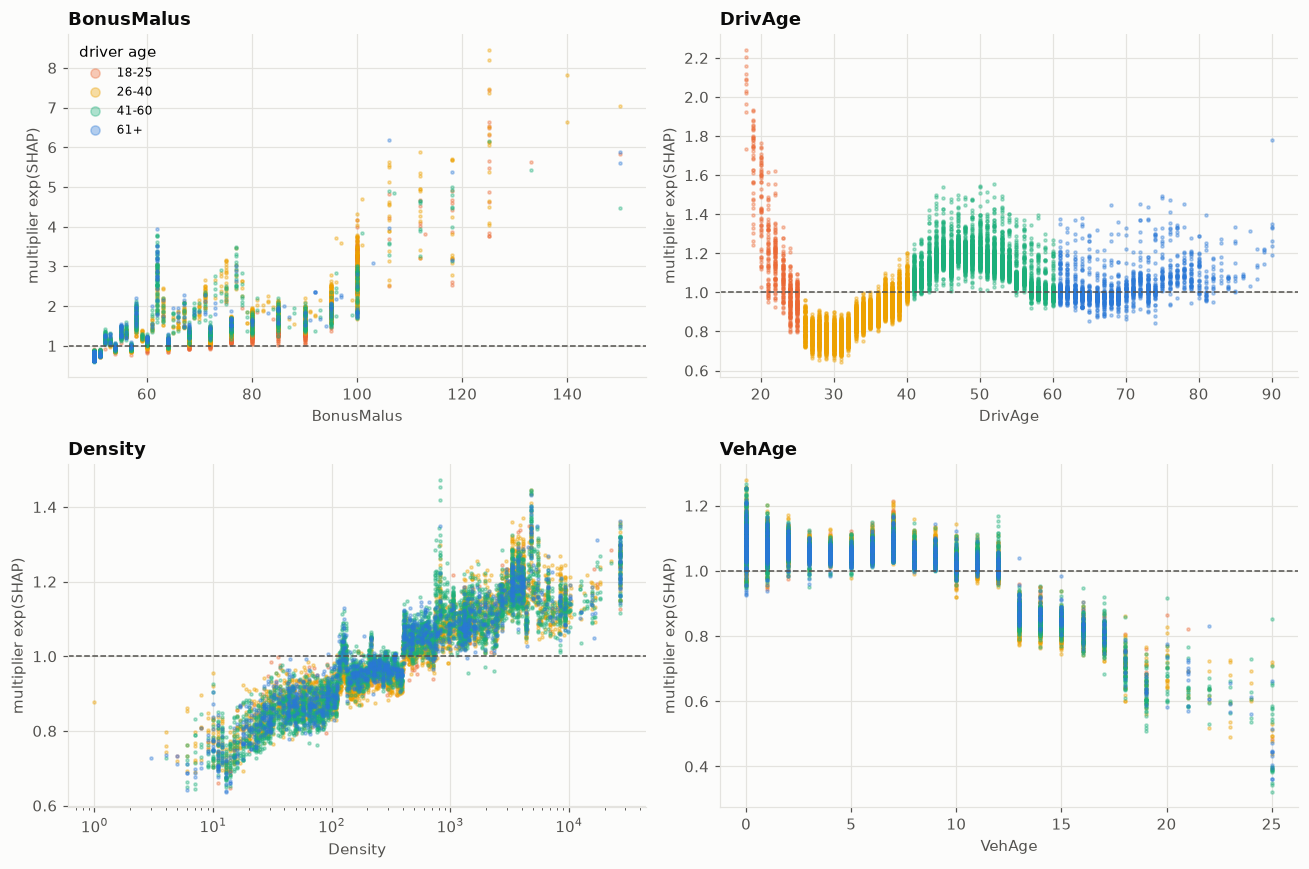

In [5]:
age_band = pd.cut(sample["DrivAge"], [17, 25, 40, 60, 100], labels=["18-25", "26-40", "41-60", "61+"])
age_colors = dict(zip(age_band.cat.categories, [SERIES[1], SERIES[3], SERIES[2], SERIES[0]]))
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, feat in zip(axes.ravel(), ["BonusMalus", "DrivAge", "Density", "VehAge"]):
    xv = sample[feat].clip(upper={"BonusMalus": 150, "DrivAge": 90, "Density": 27000, "VehAge": 25}[feat])
    for band, col in age_colors.items():
        m = (age_band == band).to_numpy()
        ax.scatter(xv[m], np.exp(shap_df[feat][m]), s=4, alpha=0.35, color=col, label=band, rasterized=True)
    if feat == "Density":
        ax.set_xscale("log")
    ax.axhline(1, color=INK_2, lw=1, ls="--")
    ax.set(title=feat, xlabel=feat, ylabel="multiplier exp(SHAP)")
axes[0, 0].legend(title="driver age", markerscale=3, fontsize=8)
plt.tight_layout(); save(fig, "06_dependence"); plt.show()

**Interpretation of each factor**

* **Driver age**: multiplier up to **~2.2 at age 18**, falling to ~0.75 around 27-32, then a clear
  **hump around 45-55 (~1.2)** and a slow rise after 70. Compared with the GLM's 7 flat age bins,
  the GBM follows the curve year by year (no arbitrary bin edges: a driver does not become
  20% safer on their 21st birthday). The 45-55 hump is the "children driving their parents' car"
  pattern seen in notebook 02.
* **Bonus-malus**: overall increasing, but **not smooth**: there are sharp spikes at specific values,
  most visibly **BM = 62** (multipliers up to ~4) and around 76-77. This has a clear explanation in the
  French bonus-malus rules: each claim-free year multiplies the coefficient by 0.95 and each at-fault
  claim by 1.25. **62 is the level reached by a driver at the 50 floor after one at-fault claim
  (50 × 1.25 = 62.5)**, whereas a driver who reaches the 60s by earning bonus from 100 passes
  through 60, 57, 54. So BM = 62 essentially flags *"a very experienced driver who has just had an
  accident"* - a much stronger warning sign than its numerical value suggests. The GLM's linear
  term cannot see this; the trees isolate these specific values. (This also explains the 61-65
  bump in the one-way analysis of notebook 02.)
* **Density**: an almost monotone increase from ~0.7 in villages to ~1.2-1.3 in cities - roughly
  linear in log-density, i.e. the GLM's functional form was right.
* **Vehicle age**: ~1.0-1.2 up to 12 years, then a steady decline to ~0.5 at 20-25 years: a gradual
  effect, not the single step at 11 years of the GLM bins.

The vertical spread at a given BM value, with colours separated (young drivers in orange-red often at
the bottom), already suggests that the effect of BM depends on age.

## 5. Interactions - where does the GBM's extra accuracy come from?

**Theory.** SHAP *interaction values* split each contribution further: $\phi_{ij}$ = main effect
$\Phi_{i,jj}$ + $\sum_{k\neq j}\Phi_{i,jk}$, where $\Phi_{i,jk}$ is the part of the prediction that
exists only *because factors $j$ and $k$ act together*. A GLM with main effects only has, by
construction, all $\Phi_{i,jk} = 0$ (on the log scale). Large off-diagonal values therefore show
exactly what the GLM cannot represent.

**Goal:** measure which pairs of factors interact in the GBM (2,000 policies: the computation is
heavier).

In [6]:
iv = explainer.shap_interaction_values(Xn.iloc[:2000])
inter = pd.DataFrame(np.abs(iv).mean(0), index=X.columns, columns=X.columns)
off = inter.where(~np.eye(len(inter), dtype=bool))
pairs = (off.stack().rename("mean |interaction|").reset_index()
         .query("level_0 < level_1").sort_values("mean |interaction|", ascending=False))
pairs["mean |interaction|"] *= 2  # Phi_jk and Phi_kj are equal halves of the pair effect
print("main effects (diagonal):"); print(pd.Series(np.diag(inter), index=X.columns).sort_values(ascending=False).round(4).to_string())
pairs.head(8).rename(columns={"level_0": "factor 1", "level_1": "factor 2"})

main effects (diagonal):
BonusMalus   0.3128
DrivAge      0.1370
Density      0.1194
VehAge       0.0925
VehGas       0.0774
Region       0.0637
VehBrand     0.0621
VehPower     0.0320


,factor 1,factor 2,mean |interaction|
26,BonusMalus,DrivAge,0.0921
31,BonusMalus,Region,0.0660
29,BonusMalus,VehBrand,0.0495
39,Density,Region,0.0348
28,BonusMalus,Density,0.0343
23,DrivAge,Region,0.0310
13,VehAge,VehBrand,0.0268
61,Region,VehBrand,0.0259


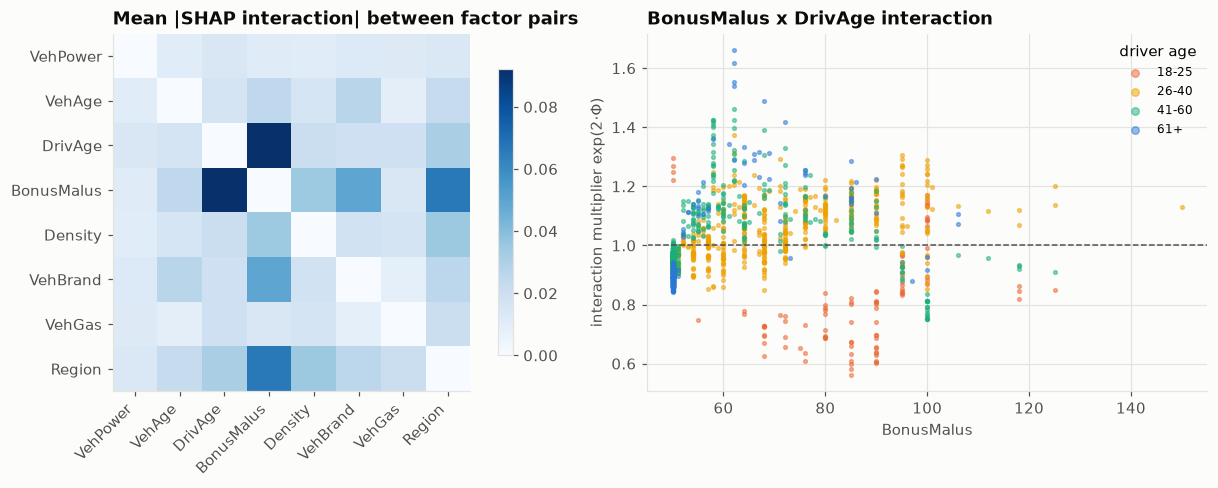

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
im = axes[0].imshow(off.fillna(0) * 2, cmap="Blues")
axes[0].set_xticks(range(len(off))); axes[0].set_xticklabels(off.columns, rotation=45, ha="right")
axes[0].set_yticks(range(len(off))); axes[0].set_yticklabels(off.index); axes[0].grid(False)
axes[0].set_title("Mean |SHAP interaction| between factor pairs")
fig.colorbar(im, ax=axes[0], shrink=0.8)
bm_age = iv[:, list(X.columns).index("BonusMalus"), list(X.columns).index("DrivAge")] * 2
s2 = sample.iloc[:2000]
band2 = age_band.iloc[:2000]
for band, col in age_colors.items():
    m = (band2 == band).to_numpy()
    axes[1].scatter(s2["BonusMalus"].clip(upper=150)[m], np.exp(bm_age[m]), s=6, alpha=0.5, color=col, label=band)
axes[1].axhline(1, color=INK_2, lw=1, ls="--")
axes[1].set(title="BonusMalus x DrivAge interaction", xlabel="BonusMalus", ylabel="interaction multiplier exp(2·Φ)")
axes[1].legend(title="driver age", markerscale=2, fontsize=8)
plt.tight_layout(); save(fig, "06_interactions"); plt.show()

**Interpretation**

* The strongest interaction by far is **BonusMalus × DrivAge** (0.092 on the log scale), followed by
  BonusMalus × Region (0.066) and BonusMalus × VehBrand (0.050). All other pairs are small.
  For comparison, the main effect of BM is 0.31: the interaction is about **30% of the BM effect** -
  far from negligible.
* The right panel shows its *direction*:
  * for **young drivers (18-25)** with BM 70-100 the interaction multiplier is **~0.6-0.8**: a high BM
    is *less* alarming for them, because it mostly reflects that they have not had time to earn bonus
    (everybody starts at 100);
  * for **drivers over 40** with BM 55-75 the multiplier is **~1.1-1.6**: an experienced driver who is
    not at the floor *must* have had recent claims, which is a stronger signal of risk.

This is exactly the hypothesis formulated in notebook 02 (section 3.1) and notebook 03: the meaning
of a bonus-malus level depends on the driver's age. A main-effects GLM charges the same BM
relativity to everyone, so it over-prices young drivers with a high BM *relative to their age* and
under-prices older drivers with a slightly degraded BM. **This interaction is the main source of the
GBM's advantage**, together with the finer shapes seen in section 4.

*Practical consequence:* an actuary could add a `BonusMalus × age-band` interaction term (or a
"years since last claim" style variable) to the GLM and recover a large part of the gain while
keeping a transparent tariff.

## 6. Partial dependence and ICE - GBM vs GLM

**Theory.** The **partial dependence** (PD) of factor $j$ at value $v$ is the average prediction when
we set factor $j$ to $v$ for *every* policy, leaving all their other characteristics unchanged:

$$PD_j(v) = \frac{1}{n}\sum_i \hat f(x_{i,1},\dots, x_{ij} := v, \dots, x_{ip})$$

It answers: *"all else equal, how does the predicted frequency change with this factor?"* - the
model-agnostic analogue of a GLM relativity curve, so it can be computed for **both** models and
compared directly (we weight the average by exposure).

**ICE** (Individual Conditional Expectation) curves show the same thing for each policy separately;
PD is their average. For a log-link GLM without interactions all ICE curves are *parallel* on the log
scale (same relativity for everybody); diverging ICE curves reveal interactions.

*Caveat:* PD forces combinations that may not exist in reality (an 18-year-old with BM = 50), and
these unrealistic points enter the average. SHAP dependence plots (section 4) do not have this
problem because they only use real policies.

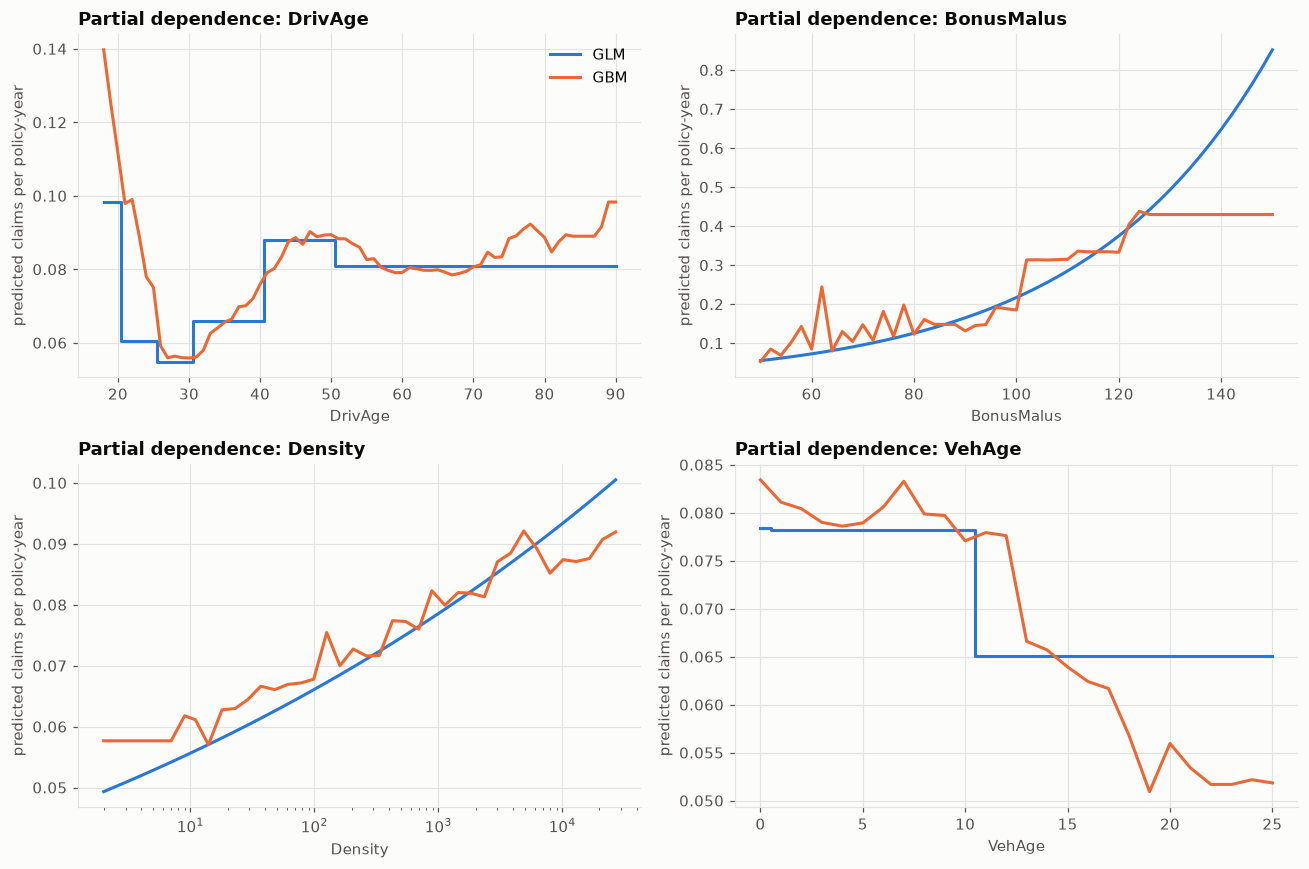

GLM    GBM
DrivAge    18    0.0984 0.1397
           32    0.0660 0.0579
           46    0.0881 0.0868
           61    0.0809 0.0805
           75    0.0810 0.0884
           90    0.0810 0.0983
BonusMalus 50    0.0552 0.0528
           70    0.0955 0.1472
           90    0.1650 0.1313
           110   0.2852 0.3148
           130   0.4928 0.4296
           150   0.8518 0.4296
Density    2     0.0493 0.0577
           14    0.0571 0.0570
           99    0.0661 0.0678
           546   0.0751 0.0773
           3838  0.0868 0.0885
           27000 0.1005 0.0919
VehAge     0     0.0784 0.0834
           5     0.0782 0.0789
           10    0.0782 0.0771
           15    0.0651 0.0639
           20    0.0651 0.0560
           25    0.0651 0.0518

In [8]:
grids = {"DrivAge": list(range(18, 91)), "BonusMalus": list(range(50, 151, 2)),
         "Density": list(np.unique(np.geomspace(2, 27000, 40).round().astype(int))), "VehAge": list(range(0, 26))}
pdp = {f: pd.DataFrame({"GLM": partial_dependence(glm, sample, f, g, n_samples=3000),
                        "GBM": partial_dependence(gbm, sample, f, g, n_samples=3000)}) for f, g in grids.items()}
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (f, t) in zip(axes.ravel(), pdp.items()):
    for model in ["GLM", "GBM"]:
        ax.plot(t.index, t[model], color=MODEL_COLORS[model], label=model, drawstyle="steps-mid" if model == "GLM" and f in ("DrivAge", "VehAge") else "default")
    if f == "Density":
        ax.set_xscale("log")
    ax.set(title=f"Partial dependence: {f}", xlabel=f, ylabel="predicted claims per policy-year")
axes[0, 0].legend()
plt.tight_layout(); save(fig, "06_pdp"); plt.show()
pd.concat({f: t.iloc[np.linspace(0, len(t) - 1, 6).astype(int)] for f, t in pdp.items()})

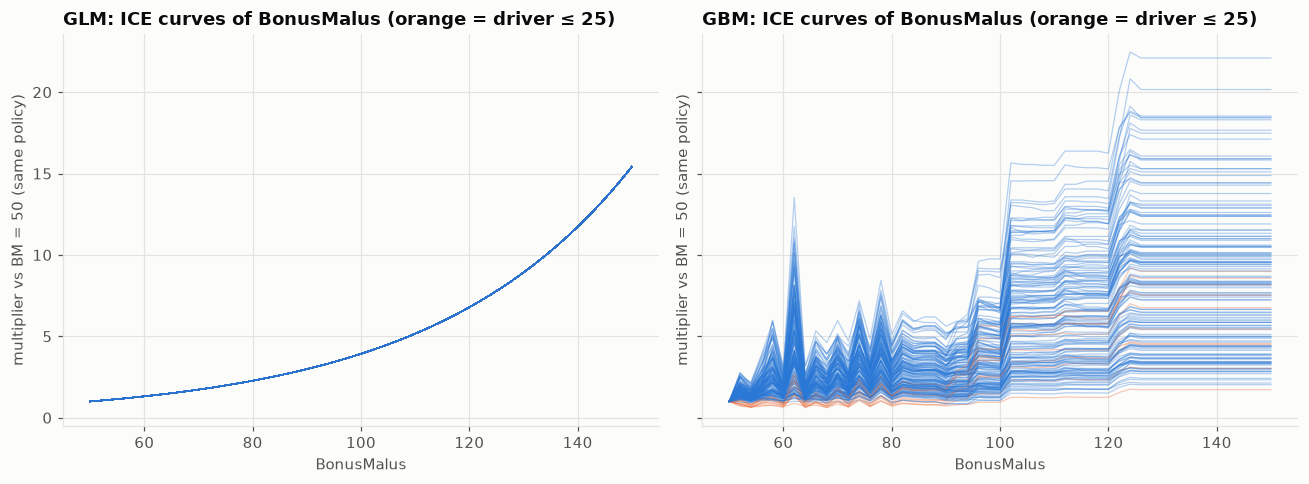

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (model, m) in zip(axes, [("GLM", glm), ("GBM", gbm)]):
    ice = ice_curves(m, sample, "BonusMalus", grids["BonusMalus"], n_samples=150, random_state=3)
    centered = np.log(ice).sub(np.log(ice[50]), axis=0)  # log-multiplier relative to BM = 50, per policy
    young = (sample.loc[ice.index, "DrivAge"] <= 25).to_numpy()
    for k, row in enumerate(centered.to_numpy()):
        ax.plot(grids["BonusMalus"], np.exp(row), color=SERIES[1] if young[k] else SERIES[0], alpha=0.35, lw=0.8)
    ax.set(title=f"{model}: ICE curves of BonusMalus (orange = driver ≤ 25)", xlabel="BonusMalus",
           ylabel="multiplier vs BM = 50 (same policy)")
plt.tight_layout(); save(fig, "06_ice_bonusmalus"); plt.show()

**Interpretation**

* **Driver age**: the two PD curves agree in the middle; the GBM is much higher for **18-year-olds**
  (0.140 vs 0.098 claims/year) and keeps rising after 70 (0.098 at 90 vs a flat 0.081 for the GLM's
  71+ bin). The GLM bins average away both extremes.
* **Bonus-malus**: the GLM is a smooth exponential; the GBM follows it on average between 50 and 120,
  with the spikes discussed above. **Above ~125 the GBM is flat (0.43) while the GLM keeps growing
  exponentially (0.85 at 150).** Trees cannot extrapolate: beyond the last split they predict a
  constant. With only 0.03% of the exposure above 150, neither model is reliable there - but the
  GLM's ×15 loading at BM 150 (left ICE panel) is driven purely by its functional form, not by data.
* **Density**: very close; the GBM is slightly flatter at the extremes (0.058 vs 0.049 in the
  emptiest villages, 0.092 vs 0.100 in Paris-like densities).
* **Vehicle age**: the GBM decreases gradually after 12 years down to ~0.052, while the GLM has a
  single step to 0.065.

**ICE curves of BonusMalus.** For the GLM all 150 curves are **identical** (a multiplier of ~4 at
BM 100 vs 50 for every policy): no interaction, by construction. For the GBM the curves **fan
out** - the same BM change multiplies the frequency by 2 for some policies and by 10+ for others -
and the curves of young drivers (orange) are systematically at the *bottom*: the age × BM
interaction, seen from another angle.

*Real-world meaning:* for pricing, these plots are how one validates a GBM - checking that each
effect has a sensible shape - and also where one sees what to **constrain** before production: e.g.
impose monotonicity in BM (LightGBM supports `monotone_constraints`) so that a customer's price
can never decrease after a claim, and cap the effect in the sparse BM > 125 region.

## 7. Local explanations - why does this customer get this price?

**Goal:** explain individual predictions, the question a customer or a regulator would ask. We
pick two contrasting policies from the test sample and decompose their predicted frequency into a
product of factor multipliers: $\hat\lambda = e^{\phi_0}\times\prod_j e^{\phi_j}$.

In [10]:
pred_sample = gbm.predict(sample)
young_risky = sample[(sample["DrivAge"] <= 21) & (sample["BonusMalus"] >= 90)].index[0]
mature_safe = sample[(sample["DrivAge"].between(45, 60)) & (sample["BonusMalus"] == 50) & (sample["Density"] < 200)].index[0]
cols = ["DrivAge", "BonusMalus", "Density", "VehAge", "VehPower", "VehBrand", "VehGas", "Region"]
cases = sample.loc[[young_risky, mature_safe], cols].copy()
cases["GBM frequency"] = gbm.predict(cases.join(sample[["Exposure", "Area"]]))
cases["GLM frequency"] = glm.predict(cases.join(sample[["Exposure", "Area"]]))
cases.index = ["policy A (young, high BM)", "policy B (mature, max bonus, rural)"]
cases

,DrivAge,BonusMalus,Density,VehAge,VehPower,VehBrand,VehGas,Region,GBM frequency,GLM frequency
"policy A (young, high BM)",20,100,8455,12,5,B2,Diesel,R82,0.4955,0.3926
"policy B (mature, max bonus, rural)",51,50,79,7,8,B10,Diesel,R24,0.0470,0.0582


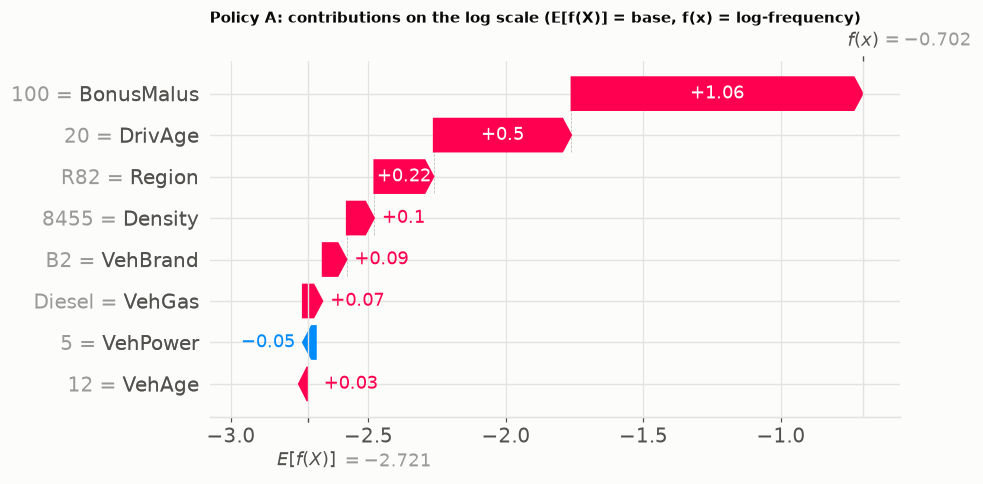

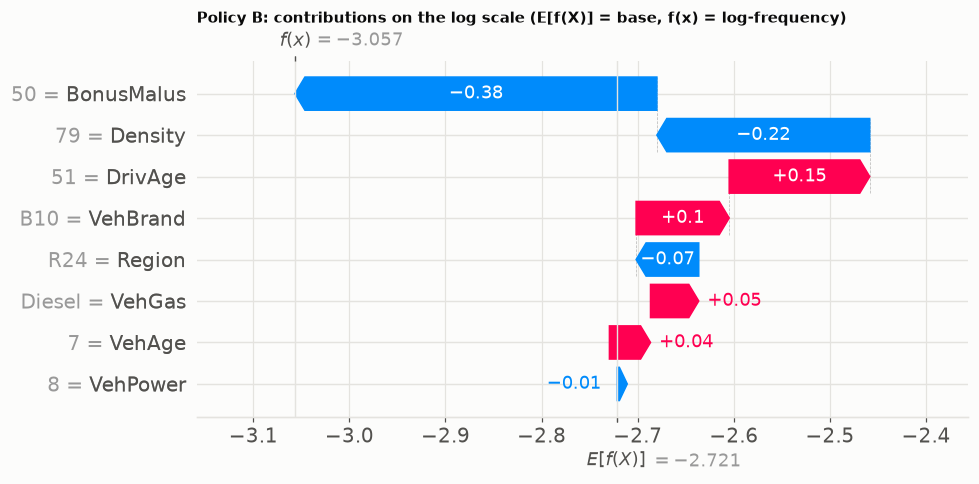

,A multiplier,B multiplier
VehPower,0.9527,0.9918
VehAge,1.0310,1.0437
DrivAge,1.6502,1.1575
BonusMalus,2.8858,0.6862
Density,1.1053,0.8013
VehBrand,1.0916,1.1017
VehGas,1.0750,1.0515
Region,1.2412,0.9369
base frequency exp(phi_0),0.0658,0.0658
= predicted frequency (product),0.4955,0.0470


In [11]:
for name, idx in [("A", young_risky), ("B", mature_safe)]:
    pos = sample.index.get_loc(idx)
    e = shap.Explanation(sv.values[pos], sv.base_values[pos], data=Xn.iloc[pos].to_numpy(),
                         display_data=X.iloc[pos].astype(str).to_numpy(), feature_names=list(X.columns))
    shap.plots.waterfall(e, max_display=9, show=False)
    plt.title(f"Policy {name}: contributions on the log scale (E[f(X)] = base, f(x) = log-frequency)", fontsize=10, loc="left")
    plt.gcf().set_size_inches(9, 4.5); plt.tight_layout(); save(plt.gcf(), f"06_waterfall_{name}"); plt.show()

table = pd.DataFrame({name: np.exp(shap_df.loc[idx]) for name, idx in [("A multiplier", young_risky), ("B multiplier", mature_safe)]})
table.loc["base frequency exp(phi_0)"] = np.exp(sv.base_values[0])
table.loc["= predicted frequency (product)"] = [np.exp(sv.base_values[0]) * np.exp(shap_df.loc[i]).prod() for i in (young_risky, mature_safe)]
table

**Interpretation**

* **Policy A** - 20 years old, BM 100, dense city (8,455 inh./km²), region R82: the GBM predicts
  **0.50 claims per year** (one claim every two years!), the GLM 0.39. The decomposition:
  base 0.066 × **2.89 (BM)** × **1.65 (age)** × 1.24 (region) × 1.11 (density) × 1.09 (brand) ×
  1.08 (diesel) × ... = 0.50. The bonus-malus is the main driver of the price, then age.
* **Policy B** - 51 years old, maximum bonus, rural (79 inh./km²), region R24: the GBM predicts
  **0.047** (one claim every ~21 years), the GLM 0.058. Main discounts: **BM 50 (×0.69)** and
  **low density (×0.80)**; age 51 is in the "parents' car" hump (×1.16).
* The ratio between the two customers' frequencies is **~10.5** for the GBM and ~6.7 for the GLM -
  the GBM segments more strongly, consistent with notebook 05.

*Real-world meaning:* this is exactly the kind of explanation an insurer must be able to give to a
customer ("your price is high mainly because of your bonus-malus and your age"). With SHAP, a GBM
tariff can be explained factor by factor, in the same multiplicative language as a GLM tariff -
the main practical obstacle to using ML in pricing is removed.

## 8. A quick look at severity

**Goal:** check what the (small) severity GBM relies on, for consistency with notebook 04.

In [12]:
sev_params = json.load(open(PROJECT_ROOT / "models" / "severity_gbm_params.json"))
sev_gbm = SeverityGBM(early_stopping_rounds=0, **sev_params).fit(train)
sev_sample = test[test["ClaimNb"] > 0]
sev_sv = shap.TreeExplainer(sev_gbm.model_.booster_)(gbm_features(sev_sample))
sev_imp = pd.Series(np.abs(sev_sv.values).mean(0), index=X.columns).sort_values(ascending=False)
age_effect = pd.Series(np.exp(sev_sv.values[:, list(X.columns).index("DrivAge")]), index=sev_sample.index).groupby(
    pd.cut(sev_sample["DrivAge"], [17, 20, 25, 30, 50, 70, 100]), observed=True).mean()
print("severity GBM - mean |SHAP|:"); print(sev_imp.round(4).to_string())
print("\naverage DrivAge multiplier on claim cost:"); print(age_effect.round(3).to_string())

severity GBM - mean |SHAP|:
Region       0.0400
VehBrand     0.0251
BonusMalus   0.0248
DrivAge      0.0204
VehAge       0.0131
VehPower     0.0065
Density      0.0051
VehGas       0.0000

average DrivAge multiplier on claim cost:
DrivAge
(17, 20]    1.1360
(20, 25]    1.0340
(25, 30]    0.9940
(30, 50]    0.9880
(50, 70]    0.9900
(70, 100]   1.0790


**Interpretation**

* All severity contributions are **small** (mean |SHAP| 0.00-0.04, vs 0.04-0.35 for frequency):
  consistent with the ~0.3-1% deviance explained in notebooks 04-05.
* The severity GBM relies most on **Region** and **VehBrand** - the two high-cardinality categorical
  factors that the GLM's F-tests found *not significant* (notebook 04). With 22 regions and 11 brands,
  categorical splits can isolate small groups with a few expensive claims: **this is over-fitting**,
  and it explains why the severity GBM does not beat the reduced GLM.
* Driver age still shows the expected pattern (×1.14 for 18-20, ×1.08 above 70), but weaker than in
  the GLM (×1.36 and ×1.28): the regularised GBM shrinks it.

This confirms the choice made in notebook 05: **GLM for severity**, **GBM for frequency**.

## 9. Conclusions

| Question | Answer |
|---|---|
| Which factors drive frequency? | Bonus-malus (~35% of the total contribution), then driver age, density, vehicle age, region, fuel, brand; vehicle power least. **Same ranking in the GLM and the GBM.** |
| How do they act? | Age: strong young-driver loading (up to ×2.2 at 18), dip at 27-32, hump at 45-55. BM: increasing, with spikes at levels that reveal a recent claim (e.g. 62 = 50 × 1.25). Density: log-linear. Vehicle age: gradual decline after 12 years. |
| Where does the GBM's gain come from? | Finer non-linear shapes (age by year, specific BM levels) and above all the **bonus-malus × driver age interaction** (~30% of the BM main effect): a high BM is less informative for a young driver than for an experienced one. |
| Can individual prices be explained? | Yes: SHAP decomposes each prediction exactly into a product of factor multipliers - the same language as a GLM tariff. |
| Caveats | SHAP/PD explain the model, not causality; PD mixes in unrealistic combinations; trees do not extrapolate (flat above BM 125) and are not monotone by default. |

**Recommended next steps for a production tariff**

1. Add monotonicity constraints in BM (and possibly age > 30) to the frequency GBM.
2. Alternatively, enrich the GLM with the BM × age interaction and a "recent claim" indicator
   derived from BM levels, to recover most of the gain in a fully transparent model.
3. Model large losses separately (notebook 05) instead of a flat loading.
4. Check fairness/regulatory constraints on proxies (e.g. region, brand) before deployment.